## PD Model
A logistic regression scorecard using Weight of Evidence (WoE). The target is default within 12 months (bad_12m)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

## Load data 
Only use loans that have had a full 12 months to show their outcome.

In [4]:
train = pd.read_parquet("../data/train.parquet")
test = pd.read_parquet("../data/test.parquet")
live = pd.read_parquet("../data/live.parquet")

train = train[train["has_12m_window"] == 1]
test = test[test["has_12m_window"] == 1]

print("Train:", train.shape, "12m default rate:", round(train["bad_12m"].mean(), 4))
print("Test:", test.shape, "12m default rate:", round(test["bad_12m"].mean(), 4))

Train: (855502, 35) 12m default rate: 0.0438
Test: (443579, 35) 12m default rate: 0.044


## Feature prep 
Columns with only a few values are treated as categories. Counts are capped at 3 so rare high values don't get their own bin.

In [5]:
num_features = ["loan_amnt", "int_rate", "emp_length", "annual_inc", "dti", "fico",
                "open_acc", "revol_util", "total_acc", "mths_since_last_delinq",
                "credit_history_years"]

cat_features = ["term", "grade", "home_ownership", "verification_status", "purpose",
                "addr_state", "delinq_2yrs", "inq_last_6mths", "pub_rec"]

def prep(df):
    df = df.copy()
    for col in ["delinq_2yrs", "inq_last_6mths", "pub_rec"]:
        df[col] = df[col].clip(upper=3)
    for col in cat_features:
        df[col] = df[col].astype(str)
    return df

train = prep(train)
test = prep(test)
live = prep(live)

## Binning and WoE 
Numeric columns are cut into 10 equal-sized bins using the train data, and missing values get their own bin. WoE = ln(% of goods / % of bads), so higher WoE means safer. Adding 0.5 to the counts avoids dividing by zero.

In [6]:
def make_edges(series, n=10):
    _, edges = pd.qcut(series, q=n, retbins=True, duplicates="drop")
    edges[0], edges[-1] = -np.inf, np.inf
    return edges

def to_bins(df, col, edges):
    if col in num_features:
        return pd.cut(df[col], bins=edges[col]).astype(str)
    return df[col]

def woe_table(bins, y):
    t = pd.DataFrame({"bin": bins, "bad": y}).groupby("bin")["bad"].agg(["count", "sum"])
    t.columns = ["n", "bad"]
    t["good"] = t["n"] - t["bad"]
    t["pct_good"] = (t["good"] + 0.5) / t["good"].sum()
    t["pct_bad"] = (t["bad"] + 0.5) / t["bad"].sum()
    t["woe"] = np.log(t["pct_good"] / t["pct_bad"])
    t["iv"] = (t["pct_good"] - t["pct_bad"]) * t["woe"]
    return t

edges = {col: make_edges(train[col]) for col in num_features}

woe = {}
for col in num_features + cat_features:
    woe[col] = woe_table(to_bins(train, col, edges), train["bad_12m"])

## Information Value 
Rule of thumb: below 0.02 is useless, 0.02–0.1 weak, 0.1–0.3 medium, above 0.3 strong. Keep features with IV ≥ 0.02.

In [7]:
iv = pd.Series({col: woe[col]["iv"].sum() for col in woe}).sort_values(ascending=False)
print(iv.round(3))

features = iv[iv >= 0.02].index.tolist()
print("\nSelected by IV:", features)

int_rate                  0.582
grade                     0.564
fico                      0.089
verification_status       0.087
inq_last_6mths            0.072
dti                       0.066
purpose                   0.035
home_ownership            0.035
credit_history_years      0.028
term                      0.025
annual_inc                0.022
addr_state                0.021
emp_length                0.010
loan_amnt                 0.008
pub_rec                   0.004
revol_util                0.004
mths_since_last_delinq    0.002
total_acc                 0.001
open_acc                  0.001
delinq_2yrs               0.000
dtype: float64

Selected by IV: ['int_rate', 'grade', 'fico', 'verification_status', 'inq_last_6mths', 'dti', 'purpose', 'home_ownership', 'credit_history_years', 'term', 'annual_inc', 'addr_state']


## Check a few WoE tables 
WoE should move in a sensible direction, e.g. higher FICO means higher WoE (safer)

In [8]:
print(woe["fico"][["n", "bad", "woe"]].round(3))
print(woe["grade"][["n", "bad", "woe"]].round(3))

                     n   bad    woe
bin                                
(-inf, 667.0]   160732  9348 -0.300
(667.0, 672.0]   77469  4136 -0.209
(672.0, 677.0]   68200  3603 -0.198
(677.0, 682.0]   67093  3382 -0.149
(682.0, 687.0]   57791  2714 -0.074
(687.0, 697.0]  106308  4603  0.011
(697.0, 707.0]   87727  3330  0.148
(707.0, 717.0]   68735  2256  0.299
(717.0, 737.0]   80550  2290  0.447
(737.0, inf]     80897  1768  0.716
          n    bad    woe
bin                      
A    144183   1407  1.535
B    252118   5830  0.659
C    252745  11180 -0.012
D    121832   9019 -0.558
E     60755   6195 -0.909
F     19151   2881 -1.353
G      4718    918 -1.664


## Transform to WoE values
Categories seen in test or live but not in train get a WoE of 0 (neutral)

In [9]:
def to_woe(df):
    X = pd.DataFrame(index=df.index)
    for col in features:
        X[col] = to_bins(df, col, edges).map(woe[col]["woe"]).fillna(0)
    return X

X_train, y_train = to_woe(train), train["bad_12m"]
X_test, y_test = to_woe(test), test["bad_12m"]
X_live = to_woe(live)

## Feature selection: p-values and coefficient signs
Backward elimination. A feature is dropped if its p-value is above 0.05, or if its coefficient is positive (with WoE inputs, every coefficient should be negative). Each round drops the worst offender and refits, until every feature passes.

In [10]:
selected = features.copy()

while True:
    logit = sm.Logit(y_train, sm.add_constant(X_train[selected])).fit(disp=0)
    pvals = logit.pvalues.drop("const")
    coefs = logit.params.drop("const")

    offenders = list(set(pvals[pvals > 0.05].index) | set(coefs[coefs > 0].index))
    if not offenders:
        break

    worst = pvals[offenders].idxmax()
    print("Dropping", worst, "| p =", round(pvals[worst], 4), "| coef =", round(coefs[worst], 3))
    selected.remove(worst)

print(logit.summary())

features = selected
X_train, X_test, X_live = X_train[features], X_test[features], X_live[features]

Dropping fico | p = 0.1063 | coef = -0.034
Dropping annual_inc | p = 0.0 | coef = 0.18
Dropping term | p = 0.0 | coef = 0.709
                           Logit Regression Results                           
Dep. Variable:                bad_12m   No. Observations:               855502
Model:                          Logit   Df Residuals:                   855492
Method:                           MLE   Df Model:                            9
Date:                Thu, 26 Nov 2026   Pseudo R-squ.:                 0.07400
Time:                        16:35:08   Log-Likelihood:            -1.4235e+05
converged:                       True   LL-Null:                   -1.5373e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -3.0887      0.006   -537.243      0.000

## Fit final logistic regression

In [11]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

coefs = pd.Series(model.coef_[0], index=features).sort_values()
print(coefs.round(3))

addr_state             -0.842
home_ownership         -0.688
int_rate               -0.510
inq_last_6mths         -0.483
dti                    -0.446
grade                  -0.393
credit_history_years   -0.354
verification_status    -0.285
purpose                -0.210
dtype: float64


## Performance: Gini and KS
Gini = 2 × AUC − 1. KS = the largest gap between the cumulative distributions of bads and goods. Similar values on train and test mean the model holds up out of time.

In [12]:
def gini_ks(y, p):
    auc = roc_auc_score(y, p)
    fpr, tpr, _ = roc_curve(y, p)
    return round(2 * auc - 1, 3), round(max(tpr - fpr), 3)

p_train = model.predict_proba(X_train)[:, 1]
p_test = model.predict_proba(X_test)[:, 1]

print("Train  Gini, KS:", gini_ks(y_train, p_train))
print("Test   Gini, KS:", gini_ks(y_test, p_test))

Train  Gini, KS: (0.439, np.float64(0.322))
Test   Gini, KS: (0.422, np.float64(0.307))


## Calibration 
Do predicted PDs match actual default rates? Checked by decile on the test set.

            pd     bad
decile                
0       0.0075  0.0075
1       0.0122  0.0138
2       0.0179  0.0198
3       0.0232  0.0268
4       0.0294  0.0310
5       0.0370  0.0365
6       0.0454  0.0471
7       0.0562  0.0564
8       0.0761  0.0763
9       0.1209  0.1246


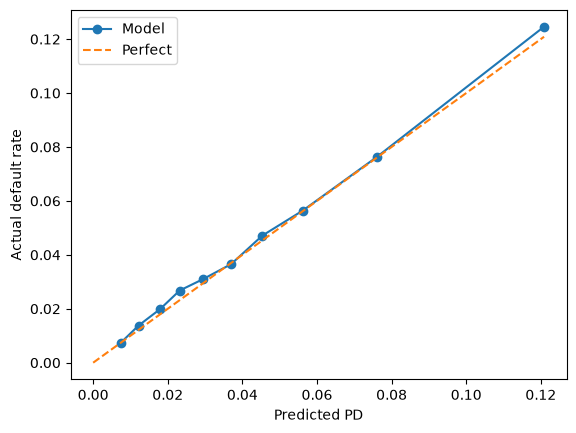

In [13]:
cal = pd.DataFrame({"pd": p_test, "bad": y_test})
cal["decile"] = pd.qcut(cal["pd"], 10, labels=False)
cal = cal.groupby("decile")[["pd", "bad"]].mean()

print(cal.round(4))

plt.plot(cal["pd"], cal["bad"], marker="o", label="Model")
plt.plot([0, cal["pd"].max()], [0, cal["pd"].max()], "--", label="Perfect")
plt.xlabel("Predicted PD")
plt.ylabel("Actual default rate")
plt.legend()
plt.show()

## Scorecard 
Scaling: 600 points = 50:1 good:bad odds, and every 20 points doubles the odds (PDO = 20). Points for each bin = −(coef × WoE + intercept / n) × factor + offset / n.

In [14]:
pdo, base_score, base_odds = 20, 600, 50
factor = pdo / np.log(2)
offset = base_score - factor * np.log(base_odds)
n = len(features)
b0 = model.intercept_[0]

rows = []
for col in features:
    for bin_name, w in woe[col]["woe"].items():
        points = -(coefs[col] * w + b0 / n) * factor + offset / n
        rows.append([col, bin_name, round(points)])

scorecard = pd.DataFrame(rows, columns=["feature", "bin", "points"])
print(scorecard.head(20))

def score(X):
    logit = model.intercept_[0] + X.values @ model.coef_[0]
    return offset - factor * logit

test["score"] = score(X_test)
print(test["score"].describe().round(0))

                feature              bin  points
0              int_rate     (-inf, 7.26]      90
1              int_rate   (11.44, 12.29]      68
2              int_rate   (12.29, 13.33]      65
3              int_rate   (13.33, 14.49]      63
4              int_rate   (14.49, 16.55]      60
5              int_rate   (16.55, 18.99]      55
6              int_rate     (18.99, inf]      48
7              int_rate     (7.26, 8.39]      82
8              int_rate     (8.39, 9.99]      76
9              int_rate    (9.99, 11.44]      73
10                grade                A      81
11                grade                B      71
12                grade                C      64
13                grade                D      58
14                grade                E      54
15                grade                F      49
16                grade                G      45
17  verification_status     Not Verified      68
18  verification_status  Source Verified      64
19  verification_sta

## Save 
Save the model, bins and scorecard for the ECL work and the Streamlit app. Score the 2018 live book too, which we need for ECL and PSI.

In [15]:
train["pd_12m"], train["score"] = p_train, score(X_train)
test["pd_12m"] = p_test
live["pd_12m"], live["score"] = model.predict_proba(X_live)[:, 1], score(X_live)

train[["id", "year", "bad_12m", "pd_12m", "score"]].to_parquet("../data/train_scored.parquet", index=False)
test[["id", "year", "bad_12m", "pd_12m", "score"]].to_parquet("../data/test_scored.parquet", index=False)
live[["id", "year", "pd_12m", "score"]].to_parquet("../data/live_scored.parquet", index=False)

scorecard.to_csv("../artifacts/scorecard.csv", index=False)
joblib.dump({"model": model, "features": features, "edges": edges, "woe": woe},
            "../artifacts/pd_model.pkl")

['../artifacts/pd_model.pkl']

## Challenger model: LightGBM 
A gradient boosting model trained on the raw features (no WoE binning), to test whether a more flexible model beats the scorecard by enough to justify being harder to explain. 20% of train is held back for early stopping, so the 2017 test set stays untouched.

In [16]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split

lgb_features = num_features + cat_features

def to_lgb(df, ref=None):
    X = df[lgb_features].copy()
    for col in cat_features:
        if ref is None:
            X[col] = X[col].astype("category")
        else:
            X[col] = pd.Categorical(X[col], categories=ref[col].cat.categories)
    return X

Xl_train = to_lgb(train)
Xl_test = to_lgb(test, ref=Xl_train)

X_fit, X_val, y_fit, y_val = train_test_split(
    Xl_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

C:\Users\Nakul\AppData\Local\Temp\ipykernel_7408\340185840.py:12: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[col] = pd.Categorical(X[col], categories=ref[col].cat.categories)


## Train LightGBM 
Stops adding trees once validation AUC hasn't improved for 50 rounds.

In [17]:
lgbm = lgb.LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=200,
    random_state=42,
    verbose=-1,
)

lgbm.fit(
    X_fit, y_fit,
    eval_set=[(X_val, y_val)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(50, verbose=False)],
)

print("Trees used:", lgbm.best_iteration_)

c:\Projects\credit-risk-modeling\crsk-venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Trees used: 167


## Champion vs challenger

In [18]:
pl_train = lgbm.predict_proba(Xl_train)[:, 1]
pl_test = lgbm.predict_proba(Xl_test)[:, 1]

comparison = pd.DataFrame({
    "model": ["Scorecard (logistic)", "LightGBM"],
    "train_gini": [gini_ks(y_train, p_train)[0], gini_ks(y_train, pl_train)[0]],
    "test_gini": [gini_ks(y_test, p_test)[0], gini_ks(y_test, pl_test)[0]],
    "test_ks": [gini_ks(y_test, p_test)[1], gini_ks(y_test, pl_test)[1]],
})
print(comparison)

comparison.to_csv("../artifacts/model_comparison.csv", index=False)

                  model  train_gini  test_gini  test_ks
0  Scorecard (logistic)       0.439      0.422    0.307
1              LightGBM       0.504      0.442    0.319


## What drives the challenger? 
Feature importance by gain (how much each feature improves the model in total).

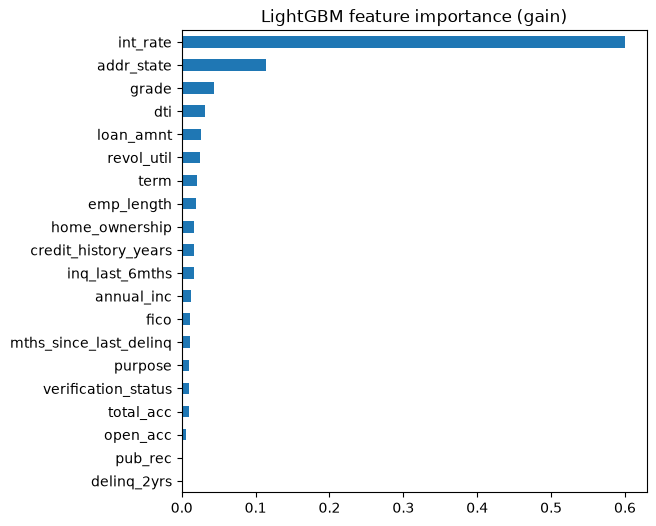

In [19]:
imp = pd.Series(lgbm.booster_.feature_importance("gain"), index=lgb_features)
imp = (imp / imp.sum()).sort_values()

imp.plot(kind="barh", figsize=(6, 6))
plt.title("LightGBM feature importance (gain)")
plt.show()

## Conclusion
  
LightGBM improves out-of-time Gini by only 2 points (0.442 vs 0.422) and shows a larger train-to-test drop (0.504 → 0.442), indicating some overfitting. The logistic scorecard is more stable over time (0.439 → 0.422) and fully transparent: points per attribute, clear reasons for declines, and simple validation. The scorecard is retained as the champion model, with LightGBM kept as a benchmark.